In [2]:
import sys
print(sys.executable)

d:\ml projects\CodeAlpha_Credit_Scoring_Model\CodeAlpha_Credit_Scoring_Model\.venv\Scripts\python.exe


In [3]:
import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Everything is working!")

Pandas: 3.0.6
NumPy: 2.5.3
Everything is working!


## 1. Load the dataset

In [4]:
import pandas as pd

columns = [
    "checking_account",
    "duration",
    "credit_history",
    "purpose",
    "credit_amount",
    "savings_account",
    "employment_since",
    "installment_rate",
    "personal_status_sex",
    "other_debtors",
    "residence_since",
    "property",
    "age",
    "other_installment_plans",
    "housing",
    "existing_credits",
    "job",
    "num_dependents",
    "telephone",
    "foreign_worker",
    "credit_risk"
]

df = pd.read_csv(
    "german.data",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 21)


### 2. View the first records

In [5]:
df.head()

,checking_account,duration,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


### 3. Check data types and missing values

In [6]:
print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Data Types:
checking_account             str
duration                   int64
credit_history               str
purpose                      str
credit_amount              int64
savings_account              str
employment_since             str
installment_rate           int64
personal_status_sex          str
other_debtors                str
residence_since            int64
property                     str
age                        int64
other_installment_plans      str
housing                      str
existing_credits           int64
job                          str
num_dependents             int64
telephone                    str
foreign_worker               str
credit_risk                int64
dtype: object

Missing Values:
checking_account           0
duration                   0
credit_history             0
purpose                    0
credit_amount              0
savings_account            0
employment_since           0
installment_rate           0
personal_status_sex        0
oth

### 4. Check the target

In [7]:
print("Credit Risk Values:")
print(df["credit_risk"].value_counts())

print("\nCredit Risk Percentages:")
print(df["credit_risk"].value_counts(normalize=True) * 100)

Credit Risk Values:
credit_risk
1    700
2    300
Name: count, dtype: int64

Credit Risk Percentages:
credit_risk
1    70.0
2    30.0
Name: proportion, dtype: float64


### 5. Check the numerical columns

In [8]:
print("Statistical Summary of Numerical Features:")
print(df.describe())

Statistical Summary of Numerical Features:
          duration  credit_amount  installment_rate  residence_since  \
count  1000.000000    1000.000000       1000.000000      1000.000000   
mean     20.903000    3271.258000          2.973000         2.845000   
std      12.058814    2822.736876          1.118715         1.103718   
min       4.000000     250.000000          1.000000         1.000000   
25%      12.000000    1365.500000          2.000000         2.000000   
50%      18.000000    2319.500000          3.000000         3.000000   
75%      24.000000    3972.250000          4.000000         4.000000   
max      72.000000   18424.000000          4.000000         4.000000   

               age  existing_credits  num_dependents  credit_risk  
count  1000.000000       1000.000000     1000.000000  1000.000000  
mean     35.546000          1.407000        1.155000     1.300000  
std      11.375469          0.577654        0.362086     0.458487  
min      19.000000          1.000000

### 6. Check the categorical features

In [9]:
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical Columns:")
print(categorical_columns)

print("\nNumber of Categories in Each Column:")
for column in categorical_columns:
    print(f"{column}: {df[column].nunique()} categories")

Categorical Columns:
Index(['checking_account', 'credit_history', 'purpose', 'savings_account',
       'employment_since', 'personal_status_sex', 'other_debtors', 'property',
       'other_installment_plans', 'housing', 'job', 'telephone',
       'foreign_worker'],
      dtype='str')

Number of Categories in Each Column:
checking_account: 4 categories
credit_history: 5 categories
purpose: 10 categories
savings_account: 5 categories
employment_since: 5 categories
personal_status_sex: 4 categories
other_debtors: 3 categories
property: 4 categories
other_installment_plans: 3 categories
housing: 3 categories
job: 4 categories
telephone: 2 categories
foreign_worker: 2 categories


C:\Users\MJKHAN\AppData\Local\Temp\ipykernel_18300\1237980841.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


### 7. Visualize Credit Risk Distribution

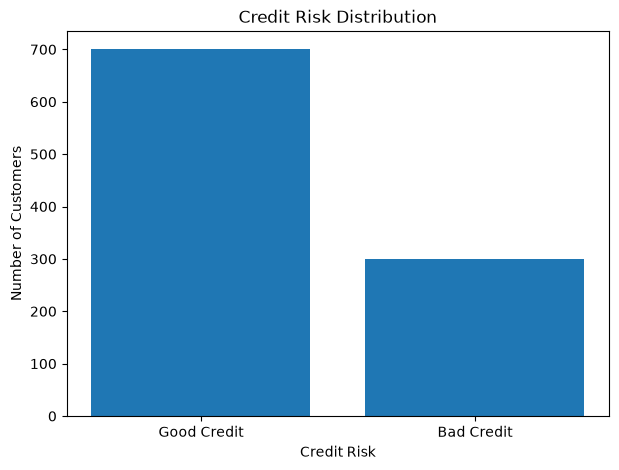

In [10]:
import matplotlib.pyplot as plt

risk_counts = df["credit_risk"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Good Credit", "Bad Credit"],
    risk_counts.values
)

plt.title("Credit Risk Distribution")
plt.xlabel("Credit Risk")
plt.ylabel("Number of Customers")
plt.show()

### 8. Credit Amount by Credit Risk

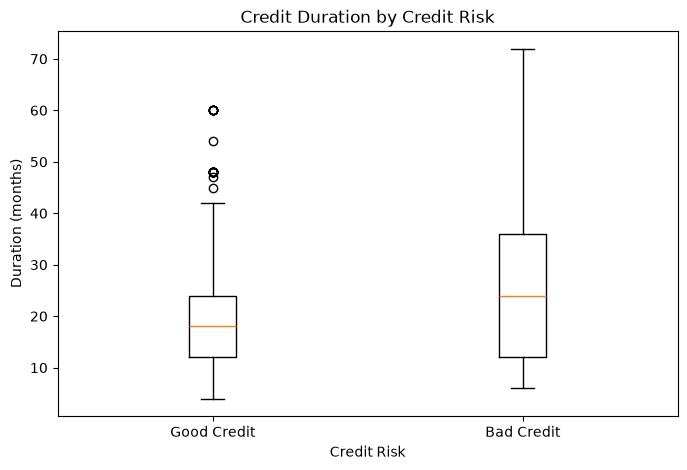

In [12]:
import matplotlib.pyplot as plt

good_duration = df[df["credit_risk"] == 1]["duration"]
bad_duration = df[df["credit_risk"] == 2]["duration"]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [good_duration, bad_duration],
    tick_labels=["Good Credit", "Bad Credit"]
)

plt.title("Credit Duration by Credit Risk")
plt.xlabel("Credit Risk")
plt.ylabel("Duration (months)")

plt.show()

### 9. Prepare the target variable

In [ ]:

df["target"] = df["credit_risk"].map({
    1: 0,
    2: 1
})

print("Target values:")
print(df["target"].value_counts())

print("\nTarget percentages:")
print(df["target"].value_counts(normalize=True) * 100)

Target values:
target
0    700
1    300
Name: count, dtype: int64

Target percentages:
target
0    70.0
1    30.0
Name: proportion, dtype: float64


### 10. Separate Features (X) and Target (y)

In [ ]:

X = df.drop(columns=["credit_risk", "target"])
y = df["target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (1000, 20)
Target shape: (1000,)

Feature columns:
['checking_account', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_account', 'employment_since', 'installment_rate', 'personal_status_sex', 'other_debtors', 'residence_since', 'property', 'age', 'other_installment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'telephone', 'foreign_worker']


### 11. Split the Data

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data:
X_train: (800, 20)
y_train: (800,)

Testing data:
X_test: (200, 20)
y_test: (200,)

Training target distribution:
target
0    560
1    240
Name: count, dtype: int64

Testing target distribution:
target
0    140
1     60
Name: count, dtype: int64


### 12. Preprocess the data

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(include="str").columns.tolist()

print("Numerical columns:", len(numerical_columns))
print("Categorical columns:", len(categorical_columns))

# Preprocess numerical features
numerical_transformer = StandardScaler()

# Preprocess categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

print("\nPreprocessor created successfully!")

Numerical columns: 7
Categorical columns: 13

Preprocessor created successfully!


### 13. Train the Logistic Regression model

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create the complete model pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions on unseen test data
y_pred_lr = logistic_model.predict(X_test)

# Evaluate the model
print("Logistic Regression Results")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    target_names=["Good Credit", "Bad Credit"],
    zero_division=0
))

Logistic Regression Results
-----------------------------------
Accuracy: 0.78

Classification Report:
              precision    recall  f1-score   support

 Good Credit       0.82      0.89      0.85       140
  Bad Credit       0.67      0.53      0.59        60

    accuracy                           0.78       200
   macro avg       0.74      0.71      0.72       200
weighted avg       0.77      0.78      0.77       200



### 14. Train a Decision Tree model

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Create the Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

# Predict on test data
y_pred_dt = decision_tree_model.predict(X_test)

# Evaluate the model
print("Decision Tree Results")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    labels=[0, 1],
    target_names=["Good Credit", "Bad Credit"],
    zero_division=0
))

Decision Tree Results
-----------------------------------
Accuracy: 0.57

Classification Report:
              precision    recall  f1-score   support

 Good Credit       0.79      0.53      0.63       140
  Bad Credit       0.38      0.67      0.48        60

    accuracy                           0.57       200
   macro avg       0.58      0.60      0.56       200
weighted avg       0.66      0.57      0.59       200



### 15. Random Forest Model 

In [23]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Create the tuned Random Forest pipeline
rf_tuned_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_leaf=2,
        class_weight={0: 1, 1: 2},
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_tuned_model.fit(X_train, y_train)

# Make predictions
y_pred_rf_tuned = rf_tuned_model.predict(X_test)

# Evaluate the model
print("Tuned Random Forest Results")
print("-" * 35)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_rf_tuned), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf_tuned,
    labels=[0, 1],
    target_names=["Good Credit", "Bad Credit"],
    zero_division=0
))

Tuned Random Forest Results
-----------------------------------
Accuracy: 0.77

Classification Report:
              precision    recall  f1-score   support

 Good Credit       0.81      0.89      0.84       140
  Bad Credit       0.65      0.50      0.57        60

    accuracy                           0.77       200
   macro avg       0.73      0.69      0.70       200
weighted avg       0.76      0.77      0.76       200



### 16. Import and Train The SVM model

In [24]:
from sklearn.svm import SVC

print("SVM imported successfully!")

SVM imported successfully!


In [25]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(class_weight="balanced", random_state=42))
])

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM Accuracy:", round(accuracy_score(y_test, y_pred_svm), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    labels=[0, 1],
    target_names=["Good Credit", "Bad Credit"],
    zero_division=0
))

SVM Accuracy: 0.76

Classification Report:
              precision    recall  f1-score   support

 Good Credit       0.88      0.76      0.82       140
  Bad Credit       0.57      0.77      0.66        60

    accuracy                           0.76       200
   macro avg       0.73      0.76      0.74       200
weighted avg       0.79      0.76      0.77       200



### 17. Compare Models

In [38]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = []

models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm,
    "Random Forest": y_pred_rf_tuned
}

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Bad Credit Precision": precision_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Bad Credit Recall": recall_score(
            y_test, predictions, pos_label=1, zero_division=0
        ),
        "Bad Credit F1-Score": f1_score(
            y_test, predictions, pos_label=1, zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

print("Credit Scoring Model Comparison")
print("-" * 75)
print(comparison_df.round(3).to_string(index=False))

Credit Scoring Model Comparison
---------------------------------------------------------------------------
              Model  Accuracy  Bad Credit Precision  Bad Credit Recall  Bad Credit F1-Score
Logistic Regression      0.78                 0.667              0.533                0.593
      Decision Tree      0.57                 0.377              0.667                0.482
                SVM      0.76                 0.575              0.767                0.657
      Random Forest      0.77                 0.652              0.500                0.566


### 18. All four confusion matrices

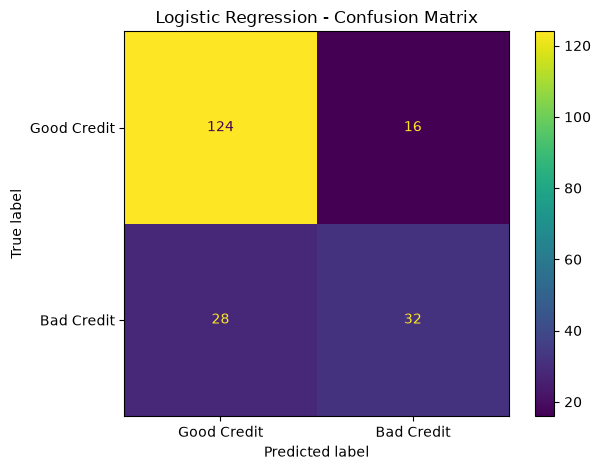

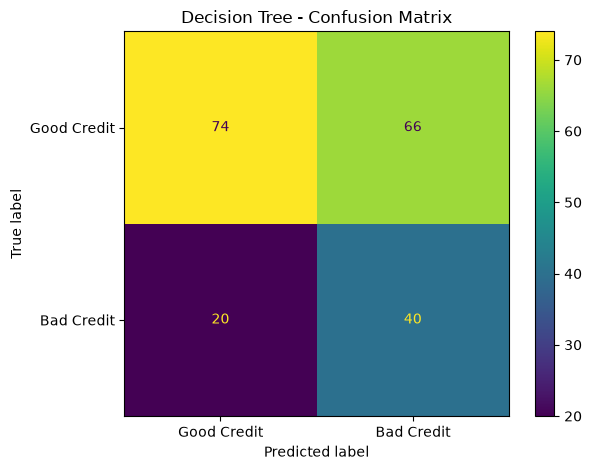

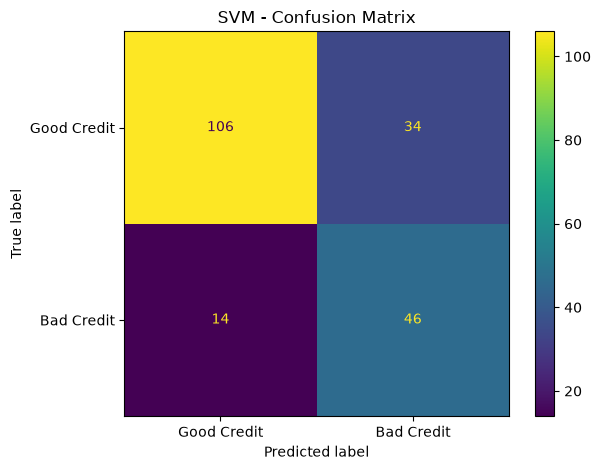

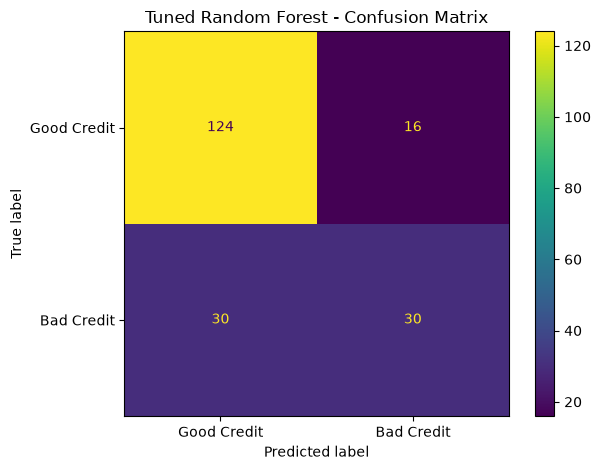

In [29]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predictions from all four models
models = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "SVM": y_pred_svm,
    "Tuned Random Forest": y_pred_rf_tuned
}

# Display a confusion matrix for each model
for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Good Credit", "Bad Credit"]
    )

    display.plot()
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

## Final Model Evaluation and Conclusion


Four machine-learning models were evaluated for credit risk classification using the German Credit dataset: Logistic Regression, Decision Tree, Support Vector Machine (SVM), and Tuned Random Forest.

* **Logistic Regression:** Achieved 78% accuracy.
* **Decision Tree:** Achieved 57% accuracy.
* **SVM:** Achieved 76% accuracy, with 76.7% recall for bad-credit applicants.
* **Tuned Random Forest:** Achieved 77% accuracy after hyperparameter tuning.

SVM correctly identified 46 of the 60 bad-credit applicants in the test set, making it the strongest candidate among the evaluated models when detecting bad-credit cases is a priority. Logistic Regression achieved the highest overall accuracy, while Tuned Random Forest showed improved performance compared with its original version.

The final model selection should consider both overall performance and the financial cost of misclassifying credit applicants. Further validation is recommended before using any model for real-world credit decisions.
